# Statistical Analysis & Visualization

Final interpretation stage: compares species-level CGI feature distributions
using z-score standardized radar charts, ANOVA, KDE, and 3-mer frequency
profiles, to complement the (largely inconclusive) clustering results.

**Input**: `dataset/processed/cpg_islands.csv`, `dataset/processed/3mer_features.csv`

**Output**: figures only (not persisted to disk)

In [ ]:
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

import numpy as np
from sklearn.manifold import TSNE

In [ ]:
islands = pd.read_csv('../dataset/processed/cpg_islands.csv')

In [ ]:
islands.head()

,id,chrom,start,end,seq,gc-content,length,obs/exp,species
0,AT1G14150,Chr1,479,807,TTCTGATAGGCGTGTAGAACAGGTGTCTGATAATCGCCGGAGATAG...,0.500000,328,0.987506,arabidopsis
1,AT1G14140,Chr1,289,507,CGACAAGCTCGTTTGCCGCCTGAACGTAATCATTCCGGCGACTCTC...,0.509174,218,1.159574,arabidopsis
2,AT1G64960,Chr1,0,211,GCCGTTCGGAGCGGGTAGAAGGATTTGTCCAGGGATTGGGCTAGCG...,0.516588,211,0.703855,arabidopsis
3,AT1G08270,Chr1,0,213,AGGAGAAGCTGCTCCGACGAATCGCCACTCTGCAGATGAGTGTAGC...,0.502347,213,1.482418,arabidopsis
4,AT1G08450,Chr1,80,515,TATAAAAGTTCCTTCTTTTCTGCGAACCTTAGAGCGATGTACCTGA...,0.505747,435,1.413750,arabidopsis
...,...,...,...,...,...,...,...,...,...
19345,BraA10g033540.4C.1,A10,1,208,GGACATGGGGGTGCTTGTTTCGAGGAAACAGCACGGGGAACATCAC...,0.502415,207,0.676471,chinese_cabbage
19346,BraA10g033560.4C.1,A10,194,607,CTGTCCACTCAGAGTTTGGCTCGCTCCATGACATCGGTCTCACGCC...,0.501211,413,0.658878,chinese_cabbage
19347,BraA10g033750.4C.1,A10,74,753,CGCTTGTACTCCTCAATGTTAACCGAAATGGGCTTTGTTAATTAAG...,0.530191,679,1.253512,chinese_cabbage
19348,BraA10g033840.4C.1,A10,0,324,CGGAAAAGGCTCCGGCAACCCAATCTGATGATGAAGCCCTAACGTC...,0.509259,324,1.005914,chinese_cabbage


In [ ]:
features_mean = {
    'gc-content': [],
    'length': [],
    'obs/exp': []
}

features_median = {
    'gc-content': [],
    'length': [],
    'obs/exp': []
}

In [ ]:
# Compute mean and median for each core CGI feature, grouped by species
# (median used later for radar chart — more robust to outliers than mean)
species = ['arabidopsis', 'mustard', 'chinese_cabbage']

for s in species:
  features_mean['gc-content'].append(islands.loc[islands['species'] == s, 'gc-content'].mean())
  features_mean['length'].append(islands.loc[islands['species'] == s, 'length'].mean())
  features_mean['obs/exp'].append(islands.loc[islands['species'] == s, 'obs/exp'].mean())

for s in species:
  features_median['gc-content'].append(islands.loc[islands['species'] == s, 'gc-content'].median())
  features_median['length'].append(islands.loc[islands['species'] == s, 'length'].median())
  features_median['obs/exp'].append(islands.loc[islands['species'] == s, 'obs/exp'].median())

In [ ]:
features_mean

{'gc-content': [np.float64(0.5097526326138677),
  np.float64(0.5506020146688209),
  np.float64(0.5154481649567384)],
 'length': [np.float64(341.6893039049236),
  np.float64(553.4570696636641),
  np.float64(385.28216109372426)],
 'obs/exp': [np.float64(1.0080272778911683),
  np.float64(1.1029717704459798),
  np.float64(1.0296018737204262)]}

In [ ]:
features_median

{'gc-content': [0.5045977254470891, 0.51875, 0.5092348284960422],
 'length': [286.5, 452.0, 343.0],
 'obs/exp': [1.0, 1.1308772998129704, 1.0222548300317926]}

In [ ]:
means = pd.DataFrame(features_mean)
medians = pd.DataFrame(features_median)

means['species'] = species
medians['species'] = species

In [ ]:
medians.head()

,gc-content,length,obs/exp,species
0,0.504598,286.5,1.000000,arabidopsis
1,0.518750,452.0,1.130877,mustard
2,0.509235,343.0,1.022255,chinese_cabbage


In [ ]:
means.head()

,gc-content,length,obs/exp,species
0,0.509753,341.689304,1.008027,arabidopsis
1,0.550602,553.457070,1.102972,mustard
2,0.515448,385.282161,1.029602,chinese_cabbage


In [ ]:
# Z-score standardize each feature's per-species median, so that GC content,
# length, and obs/exp (very different scales) can be compared on one radar chart.
# NOTE: mean/std here are computed across only 3 data points (one median per species)
# — with n=3, std is highly sensitive to each individual value.
# This chart is best read qualitatively (relative shape across species)
# rather than as a rigorous statistical comparison.
features = ['gc-content', 'length', 'obs/exp']
medians_scaled = medians.copy()

for col in features:
    avg = medians[col].mean()
    std = medians[col].std()
    medians_scaled[col] = (medians[col] - avg) / std

In [ ]:
fig = go.Figure()

for i in range(len(medians_scaled)):
    r_values = medians_scaled.loc[i, features].tolist()
    r_values.append(r_values[0])

    fig.add_trace(go.Scatterpolar(
        r=r_values,
        theta=features + [features[0]],
        fill='toself',
        name=medians.loc[i, 'species']
    ))

fig.update_layout(
    polar=dict(radialaxis=dict(visible=True)),
    title="Relative Characteristics of CpG (Z-score Standardized)",
    showlegend=True
)

fig.show()

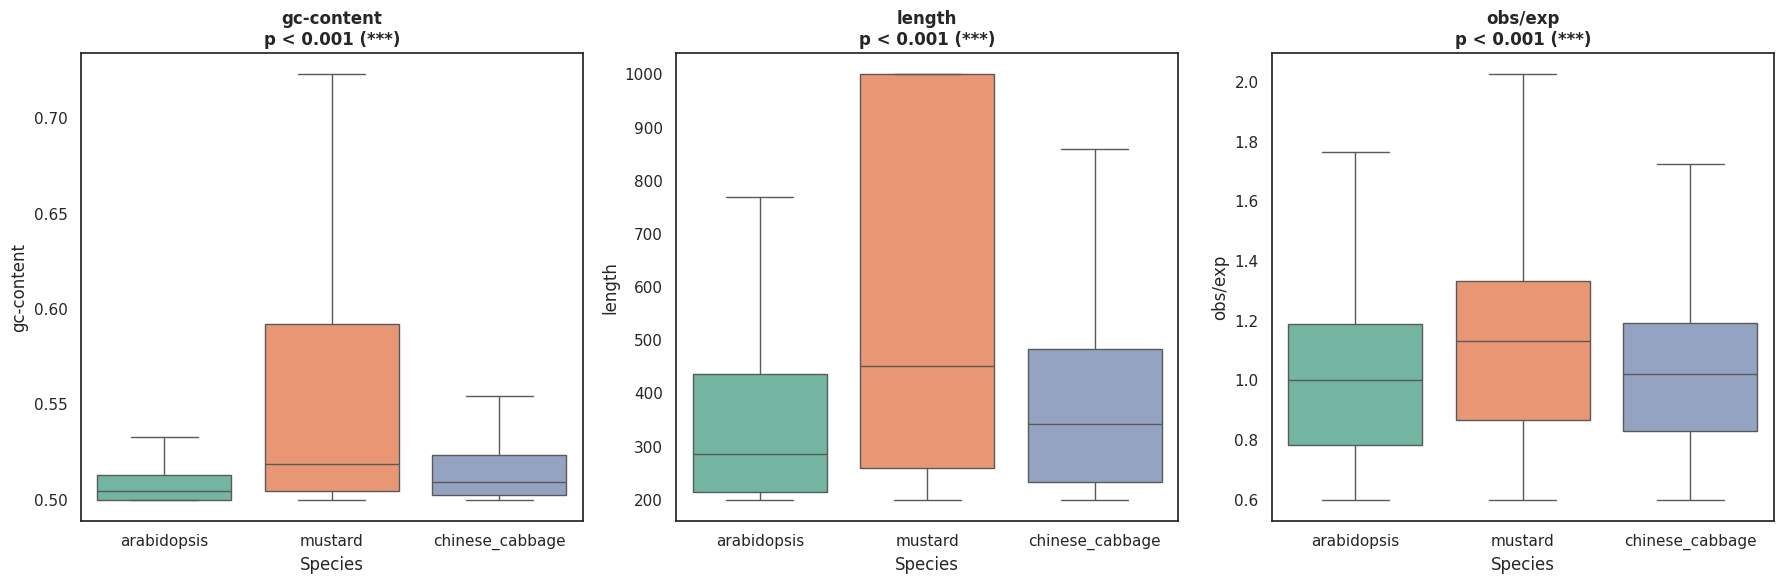

In [ ]:
# One-way ANOVA per feature to test whether species means differ significantly,
# visualized alongside box plots (outliers hidden via showfliers=False)
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, col in enumerate(features):
    #ANOVA
    groups = [islands[islands['species'] == s][col] for s in islands['species'].unique()]
    f_val, p_val = stats.f_oneway(*groups)

    #Box Plot
    sns.boxplot(data=islands, x='species', y=col, hue='species',
                ax=axes[i], palette='Set2', showfliers=False, legend=False)

    #p-value
    if p_val < 0.001:
        p_text = "p < 0.001 (***)"
    elif p_val < 0.05:
        p_text = f"p = {p_val:.3f} (*)"
    else:
        p_text = "p > 0.05 (NS)"

    axes[i].set_title(f"{col}\n{p_text}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Species")

plt.tight_layout()
plt.show()

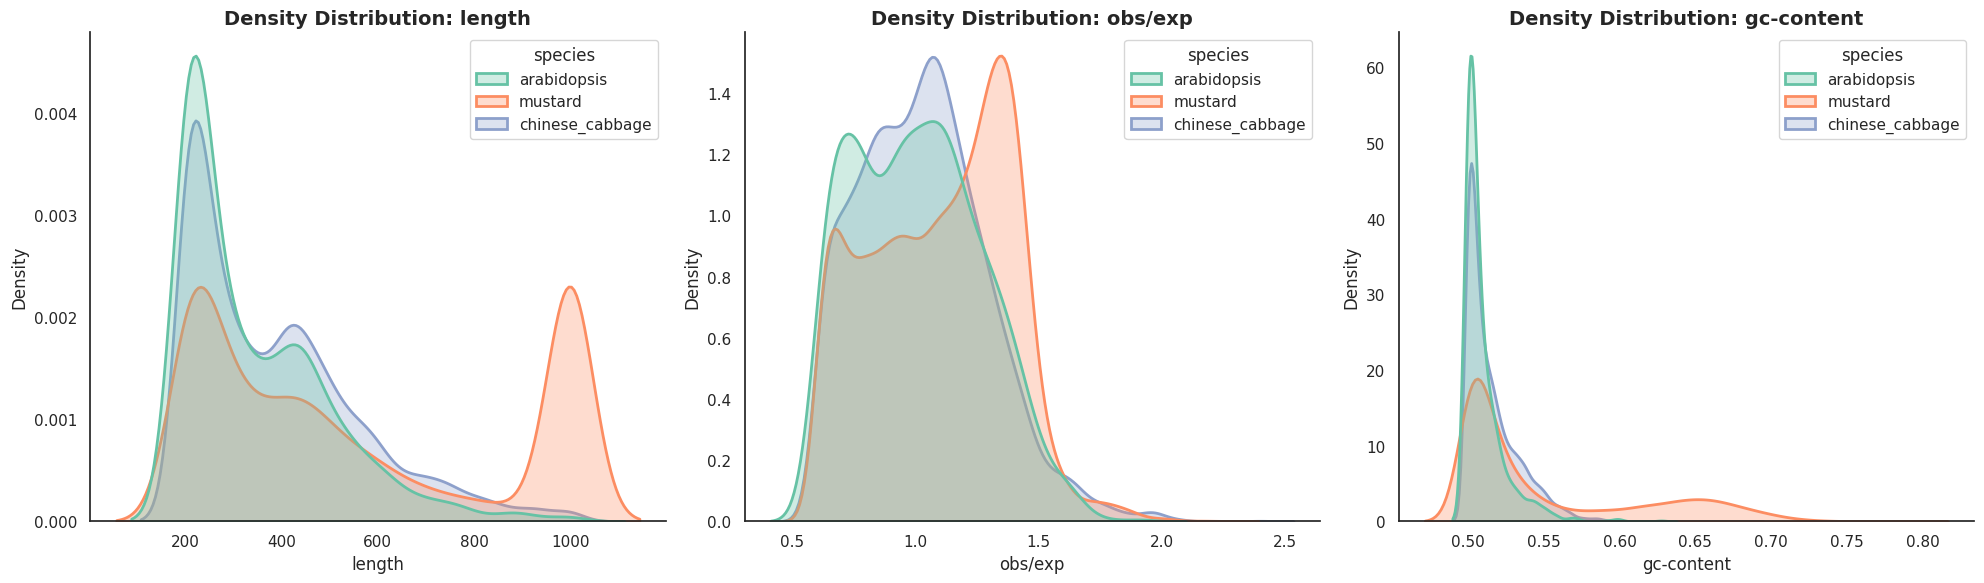

In [ ]:
sns.set_theme(style="white", rc={"font.family": "sans-serif"})

features = ['length', 'obs/exp', 'gc-content']
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(features):
  # Kernel density estimation per species, normalized independently
  # (common_norm=False) so each species' distribution shape is comparable
  # regardless of sample size differences
    sns.kdeplot(
        data=islands,
        x=col,
        hue='species',
        fill=True,
        alpha=0.3,
        linewidth=2,
        common_norm=False,
        palette='Set2',
        ax=axes[i]
    )

    axes[i].set_title(f'Density Distribution: {col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Density', fontsize=12)
    sns.despine(ax=axes[i])

plt.tight_layout()
plt.show()

In [ ]:
kmer_features = pd.read_csv('../dataset/processed/3mer_features.csv')
kmer_features['species'] = islands['species']
kmer_features

,id,AAA,AAT,AAG,AAC,ATA,ATT,ATG,ATC,AGA,...,CTC,CGA,CGT,CGG,CGC,CCA,CCT,CCG,CCC,species
0,AT1G14150,0.006098,0.018293,0.012195,0.024390,0.012195,0.012195,0.009146,0.030488,0.033537,...,0.027439,0.015244,0.006098,0.021341,0.018293,0.024390,0.012195,0.024390,0.003049,arabidopsis
1,AT1G14140,0.000000,0.018349,0.013761,0.013761,0.022936,0.004587,0.022936,0.027523,0.022936,...,0.036697,0.013761,0.022936,0.013761,0.022936,0.009174,0.032110,0.032110,0.009174,arabidopsis
2,AT1G64960,0.000000,0.004739,0.037915,0.000000,0.004739,0.009479,0.023697,0.009479,0.014218,...,0.004739,0.014218,0.009479,0.014218,0.004739,0.009479,0.009479,0.014218,0.004739,arabidopsis
3,AT1G08270,0.018779,0.018779,0.051643,0.014085,0.009390,0.014085,0.014085,0.018779,0.056338,...,0.009390,0.023474,0.009390,0.037559,0.018779,0.014085,0.000000,0.014085,0.014085,arabidopsis
4,AT1G08450,0.020690,0.018391,0.025287,0.022989,0.016092,0.013793,0.016092,0.011494,0.022989,...,0.013793,0.027586,0.025287,0.022989,0.013793,0.020690,0.013793,0.013793,0.000000,arabidopsis
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19345,BraA10g033540.4C.1,0.014493,0.000000,0.019324,0.028986,0.004831,0.019324,0.024155,0.004831,0.009662,...,0.004831,0.019324,0.009662,0.004831,0.004831,0.004831,0.009662,0.014493,0.000000,chinese_cabbage
19346,BraA10g033560.4C.1,0.033898,0.014528,0.031477,0.019370,0.007264,0.004843,0.021792,0.007264,0.007264,...,0.029056,0.007264,0.016949,0.007264,0.009685,0.031477,0.014528,0.007264,0.021792,chinese_cabbage
19347,BraA10g033750.4C.1,0.025037,0.017673,0.023564,0.020619,0.013255,0.010309,0.020619,0.007364,0.014728,...,0.014728,0.019146,0.017673,0.036819,0.013255,0.016200,0.008837,0.020619,0.002946,chinese_cabbage
19348,BraA10g033840.4C.1,0.009259,0.006173,0.030864,0.015432,0.006173,0.021605,0.015432,0.006173,0.024691,...,0.021605,0.003086,0.024691,0.015432,0.021605,0.018519,0.009259,0.024691,0.012346,chinese_cabbage


In [ ]:
kmer_cols = [col for col in kmer_features.columns if col not in ['id', 'species']]

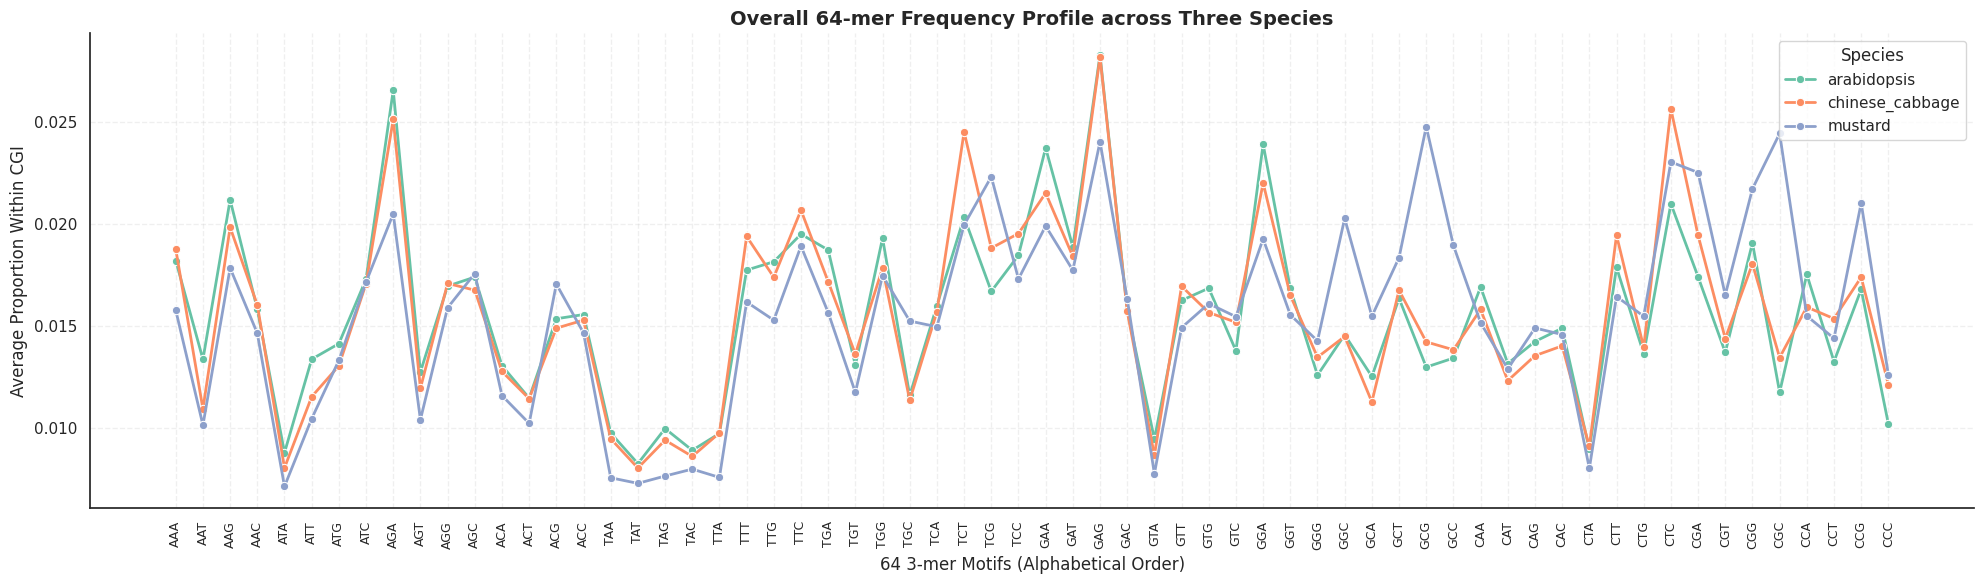

In [ ]:
#line plot visualization for means of 3-mer proportions
df_all_mean = kmer_features.groupby('species')[kmer_cols].mean().reset_index()

df_all_melted = df_all_mean.melt(id_vars='species', var_name='3-mer', value_name='Average Proportion')

df_all_melted['3-mer'] = pd.Categorical(df_all_melted['3-mer'], categories=kmer_cols, ordered=True)

plt.figure(figsize=(20, 6))
sns.lineplot(
    data=df_all_melted,
    x='3-mer',
    y='Average Proportion',
    hue='species',
    marker='o',
    linewidth=2,
    palette='Set2'
)

plt.xticks(rotation=90, fontsize=9)
plt.grid(True, alpha=0.3, linestyle='--')

plt.title('Overall 64-mer Frequency Profile across Three Species', fontsize=14, fontweight='bold')
plt.xlabel('64 3-mer Motifs (Alphabetical Order)', fontsize=12)
plt.ylabel('Average Proportion Within CGI', fontsize=12)
plt.legend(title='Species', loc='upper right')
sns.despine()
plt.tight_layout()
plt.show()

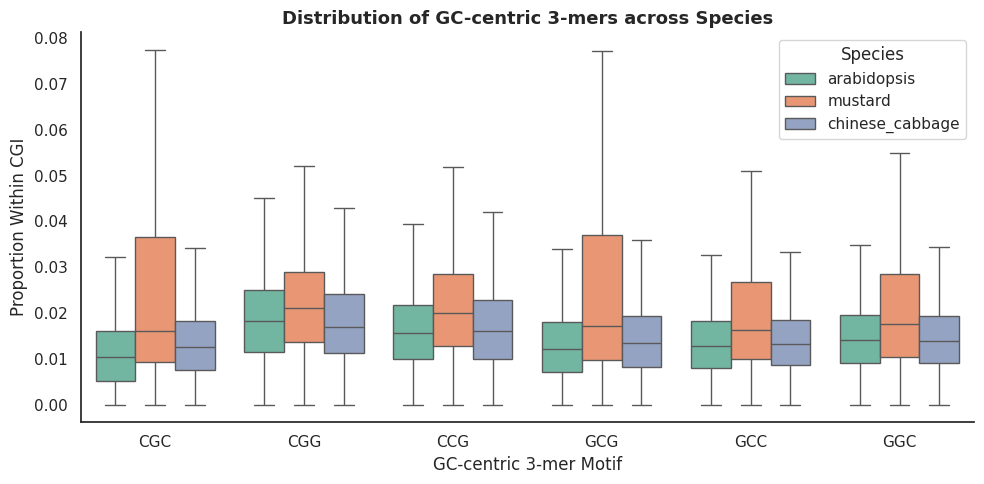

In [ ]:
# Visualize only GC-centric 3-mers (previously flagged as important by
# the decision tree's feature importance)
gc_target_kmers = ['CGC', 'CGG', 'CCG', 'GCG', 'GCC', 'GGC']

df_gc = kmer_features[['species'] + gc_target_kmers]
df_gc_melted = df_gc.melt(id_vars='species', var_name='GC-centric 3-mer', value_name='Proportion')

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_gc_melted,
    x='GC-centric 3-mer',
    y='Proportion',
    hue='species',
    palette='Set2',
    showfliers=False
)

plt.title('Distribution of GC-centric 3-mers across Species', fontsize=13, fontweight='bold')
plt.xlabel('GC-centric 3-mer Motif')
plt.ylabel('Proportion Within CGI')
plt.legend(title='Species')
sns.despine()
plt.tight_layout()
plt.show()